# Spherical-inclined orbits: batched k-mode amplitudes and fluxes

Increment B of the GPU/JAX port (`dev/PHASE5B.md`): Teukolsky amplitudes for
e = 0, inclined orbits as 1D Fourier coefficients over the polar period.
This demo builds (l, m, k) flux towers across inclinations. Assertions are
embedded so re-executing the notebook is itself a test.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import jax
from hblteuk.geo import MiniGeo
from hblteuk.jax import solve_spherical_mode_table, flux_modes

A, P = 0.9, 10.0
LMAX, KMAX = 6, 5
modes = [(l, m, k) for l in range(2, LMAX + 1) for m in range(-l, l + 1)
         for k in range(-KMAX, KMAX + 1) if not (m == 0 and k == 0)]
l_arr = np.array([c[0] for c in modes])
m_arr = np.array([c[1] for c in modes])
k_arr = np.array([c[2] for c in modes])
print(f"{len(modes)} modes, lmax = {LMAX}, |k| <= {KMAX}")

490 modes, lmax = 6, |k| <= 5


In [2]:
xs = [0.4, 0.6, 0.8, 0.95]
sols, fluxes = {}, {}
for x in xs:
    orbit = MiniGeo(A, P, 0.0, x)
    sol = solve_spherical_mode_table(orbit, -2, l_arr, m_arr, k_arr)
    fx = flux_modes(sol.amplitudes, sol.m, sol.omega, sol.eigenvalues, A)
    sols[x], fluxes[x] = sol, fx
    err = float(np.max(np.asarray(sol.errors)))
    print(f"x = {x}: max relative error estimate {err:.2e}")
    # near-equatorial orbits (x = 0.95) push high-|k| amplitudes toward
    # zero, so the cancellation floor inflates the RELATIVE estimate for
    # those tiny modes (~2e-6 observed); estimator overestimates by design
    assert err < 1e-4

x = 0.4: max relative error estimate 1.51e-08


x = 0.6: max relative error estimate 2.25e-08


x = 0.8: max relative error estimate 8.26e-08


x = 0.95: max relative error estimate 2.08e-06


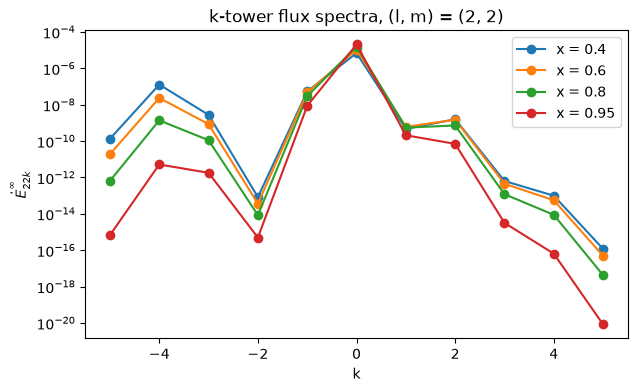

In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
for x in xs:
    sel = (l_arr == 2) & (m_arr == 2)
    edot = np.asarray(fluxes[x].Edot)[sel, 0]
    ax.semilogy(k_arr[sel], edot, "o-", label=f"x = {x}")
    # spectral falloff: the tower edges sit far below the peak
    assert edot.max() / max(edot[k_arr[sel] == -KMAX][0],
                            edot[k_arr[sel] == KMAX][0]) > 1e3
ax.set_xlabel("k"); ax.set_ylabel(r"$\dot{E}^\infty_{22k}$")
ax.set_title("k-tower flux spectra, (l, m) = (2, 2)"); ax.legend()
plt.show()

x = 0.4: Edot_inf = 5.514115e-05, superradiant modes: 348/490
x = 0.6: Edot_inf = 5.332825e-05, superradiant modes: 348/490
x = 0.8: Edot_inf = 5.178145e-05, superradiant modes: 348/490
x = 0.95: Edot_inf = 5.078840e-05, superradiant modes: 348/490


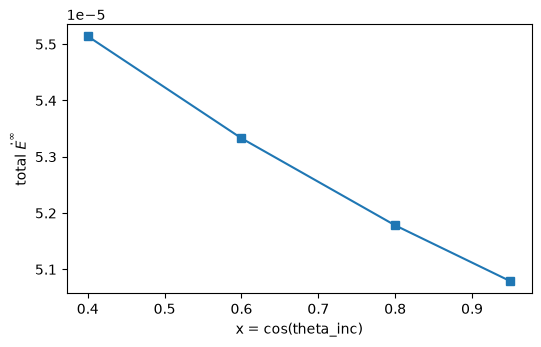

In [4]:
tot = {x: float(np.asarray(fluxes[x].Edot)[:, 0].sum()) for x in xs}
for x in xs:
    hor = np.asarray(fluxes[x].Edot)[:, 1]
    print(f"x = {x}: Edot_inf = {tot[x]:.6e}, "
          f"superradiant modes: {(hor < 0).sum()}/{len(hor)}")
    assert tot[x] > 0
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(xs, [tot[x] for x in xs], "s-")
ax.set_xlabel("x = cos(theta_inc)"); ax.set_ylabel(r"total $\dot{E}^\infty$")
plt.show()